#Simple Data Engineering Project - v1

## Objective

Demonstrate a basic data engineering pipeline by ingesting
data from an API and CSV source, transforming and joining the
data, and storing the resulting dataset in Parquet format.

## Architecture

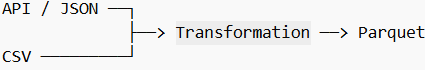
## Concepts Demonstrated

- API ingestion
- CSV ingestion
- JSON
- Data transformation
- Data joining
- Data validation
- Parquet
- Compression

#  INGESTION

## SOURCE: API

In [ ]:
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
creds = pd.read_json('/content/drive/MyDrive/Data/creds.json', typ='series')

In [ ]:
!pip install pyngrok

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Data/SalesOrderItems.csv")
df = df.fillna("")
json_data = df.to_dict(orient="records")

#print(json_data)

In [ ]:
for i in range(0,len(df.columns)):
  print(df.columns[i], type(df.columns[i]))

SALESORDERID <class 'str'>
SALESORDERITEM <class 'str'>
PRODUCTID <class 'str'>
NOTEID <class 'str'>
CURRENCY <class 'str'>
GROSSAMOUNT <class 'str'>
NETAMOUNT <class 'str'>
TAXAMOUNT <class 'str'>
ITEMATPSTATUS <class 'str'>
OPITEMPOS <class 'str'>
QUANTITY <class 'str'>
QUANTITYUNIT <class 'str'>
DELIVERYDATE <class 'str'>


In [ ]:
def get_salesorderitems_json(json_data, rows=10):
    return json_data[:rows]

In [ ]:
from fastapi import FastAPI, Depends, HTTPException, status, Header, Query
from fastapi.security import HTTPBasic, HTTPBasicCredentials
import secrets

app = FastAPI()

security = HTTPBasic()

USERNAME = "adfuser"
PASSWORD = "adfpassword"

def authenticate(credentials: HTTPBasicCredentials = Depends(security)):

    username_ok = secrets.compare_digest(
        credentials.username,
        USERNAME
    )

    password_ok = secrets.compare_digest(
        credentials.password,
        PASSWORD
    )

    if not (username_ok and password_ok):
        raise HTTPException(
            status_code=status.HTTP_401_UNAUTHORIZED,
            detail="Invalid username or password",
            headers={"WWW-Authenticate": "Basic"},
        )

    return credentials.username


@app.get("/Sales_Open_Item")
def get_customers(
    user: str = Depends(authenticate),
    rows: int = Query(10)
    ):

    return get_salesorderitems_json(json_data, rows)

In [ ]:
import nest_asyncio
import uvicorn
from threading import Thread

nest_asyncio.apply()

def run():
    uvicorn.run(app, host="0.0.0.0", port=8000)

server = Thread(target=run)
server.start()

INFO:     Started server process [4679]


Link to ngrok: https://dashboard.ngrok.com/get-started/your-authtoken

In [ ]:
from pyngrok import ngrok
ngrok.set_auth_token(creds.AUTHTOKEN)
public_url = ngrok.connect(
    addr=8000,
    domain=None
)
print(public_url)

INFO:     Waiting for application startup.
INFO:     Application startup complete.
ERROR:    [Errno 98] error while attempting to bind on address ('0.0.0.0', 8000): address already in use
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.


NgrokTunnel: "https://mayday-seltzer-parish.ngrok-free.dev" -> "http://localhost:8000"


In [ ]:
import requests

try:
    requests.get("http://127.0.0.1:8000")
    print("Port 8000 is occupied")
except:
    print("Port 8000 is free")

INFO:     127.0.0.1:56844 - "GET / HTTP/1.1" 404 Not Found
Port 8000 is occupied


In [ ]:
import requests

response = requests.get(
    "https://mayday-seltzer-parish.ngrok-free.dev/Sales_Open_Item?rows=1",
    auth=(creds.USERNAME, creds.PASSWORD)
)

print(response.status_code)
print(response.text)

INFO:     34.80.132.185:0 - "GET /Sales_Open_Item?rows=1 HTTP/1.1" 200 OK
200
[{"SALESORDERID":500000000,"SALESORDERITEM":10,"PRODUCTID":"MB-1034","NOTEID":" ","CURRENCY":"USD","GROSSAMOUNT":2499,"NETAMOUNT":2186.625,"TAXAMOUNT":312.375,"ITEMATPSTATUS":"I","OPITEMPOS":"","QUANTITY":4,"QUANTITYUNIT":"EA","DELIVERYDATE":20180311}]


In [ ]:
print(ngrok.get_tunnels())

[<NgrokTunnel: "https://mayday-seltzer-parish.ngrok-free.dev" -> "http://localhost:8000">]


In [ ]:
import requests

response = requests.get(
    "https://mayday-seltzer-parish.ngrok-free.dev/Sales_Open_Item",
    auth=("adfuser", "adfpassword")
)

pdSalesOpenItem = pd.read_json(response.text)

INFO:     34.80.132.185:0 - "GET /Sales_Open_Item HTTP/1.1" 200 OK


/tmp/ipykernel_4679/632372187.py:8: FutureWarning: Passing literal json to 'read_json' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  pdSalesOpenItem = pd.read_json(response.text)


## SOURCE: CSV

In [ ]:
pdSalesOrders = pd.read_csv("/content/drive/MyDrive/Data/SalesOrders.csv")
pdSalesOrders.head()

,SALESORDERID,CREATEDBY,CREATEDAT,CHANGEDBY,CHANGEDAT,FISCVARIANT,FISCALYEARPERIOD,NOTEID,PARTNERID,SALESORG,CURRENCY,GROSSAMOUNT,NETAMOUNT,TAXAMOUNT,LIFECYCLESTATUS,BILLINGSTATUS,DELIVERYSTATUS
0,500000000,4,20180111,4,20180116,K4,2018001,NaN,100000022,APJ,USD,13587,11888.625,1698.375,C,C,C
1,500000001,2,20180112,2,20180115,K4,2018001,NaN,100000026,EMEA,USD,12622,11044.250,1577.750,C,C,C
2,500000002,5,20180115,5,20180120,K4,2018001,NaN,100000018,APJ,USD,45655,39948.125,5706.875,C,C,C
3,500000003,3,20180115,3,20180120,K4,2018001,NaN,100000009,EMEA,USD,101786,89062.750,12723.250,C,C,C
4,500000004,8,20180116,8,20180117,K4,2018001,NaN,100000025,EMEA,USD,71684,62723.500,8960.500,C,C,C


# TRANSFORMATION

## Cleansing and Profiling

In [ ]:
import random as rand
import math

In [ ]:
pdSalesOpenItem.head()

,SALESORDERID,SALESORDERITEM,PRODUCTID,NOTEID,CURRENCY,GROSSAMOUNT,NETAMOUNT,TAXAMOUNT,ITEMATPSTATUS,OPITEMPOS,QUANTITY,QUANTITYUNIT,DELIVERYDATE
0,500000000,10,MB-1034,,USD,2499,2186.625,312.375,I,,4,EA,20180311
1,500000000,20,CB-1161,,USD,399,349.125,49.875,I,,9,EA,20180311
2,500000001,10,HB-1175,,USD,899,786.625,112.375,I,,2,EA,20180228
3,500000001,20,RC-1056,,USD,2499,2186.625,312.375,I,,2,EA,20180228
4,500000001,30,CC-1021,,USD,1144,1001.000,143.000,I,,3,EA,20180228


In [ ]:
pdSalesOpenItem.info()
#pdSalesOpenItem.isnull().sum()
#Note: No null value found therefore no cleansing needs to be applied.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   SALESORDERID    10 non-null     int64  
 1   SALESORDERITEM  10 non-null     int64  
 2   PRODUCTID       10 non-null     object 
 3   NOTEID          10 non-null     object 
 4   CURRENCY        10 non-null     object 
 5   GROSSAMOUNT     10 non-null     int64  
 6   NETAMOUNT       10 non-null     float64
 7   TAXAMOUNT       10 non-null     float64
 8   ITEMATPSTATUS   10 non-null     object 
 9   OPITEMPOS       10 non-null     object 
 10  QUANTITY        10 non-null     int64  
 11  QUANTITYUNIT    10 non-null     object 
 12  DELIVERYDATE    10 non-null     int64  
dtypes: float64(2), int64(5), object(6)
memory usage: 1.1+ KB


In [ ]:
pdSalesOrders.head()

,SALESORDERID,CREATEDBY,CREATEDAT,CHANGEDBY,CHANGEDAT,FISCVARIANT,FISCALYEARPERIOD,NOTEID,PARTNERID,SALESORG,CURRENCY,GROSSAMOUNT,NETAMOUNT,TAXAMOUNT,LIFECYCLESTATUS,BILLINGSTATUS,DELIVERYSTATUS
0,500000000,4,20180111,4,20180116,K4,2018001,NaN,100000022,APJ,USD,13587,11888.625,1698.375,C,C,C
1,500000001,2,20180112,2,20180115,K4,2018001,NaN,100000026,EMEA,USD,12622,11044.250,1577.750,C,C,C
2,500000002,5,20180115,5,20180120,K4,2018001,NaN,100000018,APJ,USD,45655,39948.125,5706.875,C,C,C
3,500000003,3,20180115,3,20180120,K4,2018001,NaN,100000009,EMEA,USD,101786,89062.750,12723.250,C,C,C
4,500000004,8,20180116,8,20180117,K4,2018001,NaN,100000025,EMEA,USD,71684,62723.500,8960.500,C,C,C


In [ ]:
pdSalesOpenItem.info()
#pdSalesOpenItem.isnull().sum()
#Note: No null value found therefore no cleansing needs to be applied.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   SALESORDERID    10 non-null     int64  
 1   SALESORDERITEM  10 non-null     int64  
 2   PRODUCTID       10 non-null     object 
 3   NOTEID          10 non-null     object 
 4   CURRENCY        10 non-null     object 
 5   GROSSAMOUNT     10 non-null     int64  
 6   NETAMOUNT       10 non-null     float64
 7   TAXAMOUNT       10 non-null     float64
 8   ITEMATPSTATUS   10 non-null     object 
 9   OPITEMPOS       10 non-null     object 
 10  QUANTITY        10 non-null     int64  
 11  QUANTITYUNIT    10 non-null     object 
 12  DELIVERYDATE    10 non-null     int64  
dtypes: float64(2), int64(5), object(6)
memory usage: 1.1+ KB


In [ ]:
#Profiling
#pdSalesOpenItem.describe()
#print(pdSalesOpenItem.count())
SALESORDERID_CHECK = int(pdSalesOpenItem[['SALESORDERID']].drop_duplicates().count()['SALESORDERID'])
print(SALESORDERID_CHECK)

3


In [ ]:
#Profiling
#pdSalesOrders.describe()
#print(pdSalesOrders.count())
print(pdSalesOrders[['SALESORDERID']].drop_duplicates().count())

SALESORDERID    334
dtype: int64


## Transformation

In [ ]:
#Two transactional tables are being joined
pdJoinedSalesData = pdSalesOpenItem.merge(pdSalesOrders, on='SALESORDERID', suffixes=('_SalesOpenItem', '_SalesOrders'))[['SALESORDERID', 'SALESORDERITEM','PARTNERID','SALESORG','GROSSAMOUNT_SalesOpenItem','NETAMOUNT_SalesOpenItem','QUANTITY']]

Validation

In [ ]:
# Validation:
if SALESORDERID_CHECK == int(pdJoinedSalesData[['SALESORDERID']].drop_duplicates().count()['SALESORDERID']):
  print("MATCH")
else:
  print("NO MATCH")

MATCH


In [ ]:
unmatched = pdSalesOpenItem[
    ~pdSalesOpenItem["SALESORDERID"].isin(
        pdSalesOrders["SALESORDERID"]
    )
]

print("Unmatched records:", len(unmatched))

Unmatched records: 0


In [ ]:
print("Source records:", len(pdSalesOpenItem))
print("Joined records:", len(pdJoinedSalesData))

Source records: 10
Joined records: 10


In [ ]:
pdJoinedSalesData.head()

,SALESORDERID,SALESORDERITEM,PARTNERID,SALESORG,GROSSAMOUNT_SalesOpenItem,NETAMOUNT_SalesOpenItem,QUANTITY
0,500000000,10,100000022,APJ,2499,2186.625,4
1,500000000,20,100000022,APJ,399,349.125,9
2,500000001,10,100000026,EMEA,899,786.625,2
3,500000001,20,100000026,EMEA,2499,2186.625,2
4,500000001,30,100000026,EMEA,1144,1001.000,3


In [ ]:
### Business Rule

#NETAMOUNT represents the net price per unit.
#Therefore:

#TotalSales = NETAMOUNT × QUANTITY

pdJoinedSalesData['TotalSales'] = pdJoinedSalesData['NETAMOUNT_SalesOpenItem']*pdJoinedSalesData['QUANTITY']

In [ ]:
pdJoinedSalesData.head()

,SALESORDERID,SALESORDERITEM,PARTNERID,SALESORG,GROSSAMOUNT_SalesOpenItem,NETAMOUNT_SalesOpenItem,QUANTITY,TotalSales
0,500000000,10,100000022,APJ,2499,2186.625,4,8746.500
1,500000000,20,100000022,APJ,399,349.125,9,3142.125
2,500000001,10,100000026,EMEA,899,786.625,2,1573.250
3,500000001,20,100000026,EMEA,2499,2186.625,2,4373.250
4,500000001,30,100000026,EMEA,1144,1001.000,3,3003.000


#Load

In [ ]:
pdJoinedSalesData.to_parquet('output.parquet', engine='pyarrow', compression='snappy')

In [ ]:
#Output Validation
print("Final row count:", len(pdJoinedSalesData))
print("Final columns:")
print(pdJoinedSalesData.columns.tolist())

Final row count: 10
Final columns:
['SALESORDERID', 'SALESORDERITEM', 'PARTNERID', 'SALESORG', 'GROSSAMOUNT_SalesOpenItem', 'NETAMOUNT_SalesOpenItem', 'QUANTITY', 'TotalSales']


In [ ]:
import os

print("Output file size:",
      os.path.getsize("output.parquet"),
      "bytes")

Output file size: 6162 bytes


In [ ]:
validation_df = pd.read_parquet("output.parquet")

print(validation_df.shape)
validation_df.head()

(10, 8)


,SALESORDERID,SALESORDERITEM,PARTNERID,SALESORG,GROSSAMOUNT_SalesOpenItem,NETAMOUNT_SalesOpenItem,QUANTITY,TotalSales
0,500000000,10,100000022,APJ,2499,2186.625,4,8746.500
1,500000000,20,100000022,APJ,399,349.125,9,3142.125
2,500000001,10,100000026,EMEA,899,786.625,2,1573.250
3,500000001,20,100000026,EMEA,2499,2186.625,2,4373.250
4,500000001,30,100000026,EMEA,1144,1001.000,3,3003.000


#Analysis

Here we want to analyze the data to check total sales per Salesorg

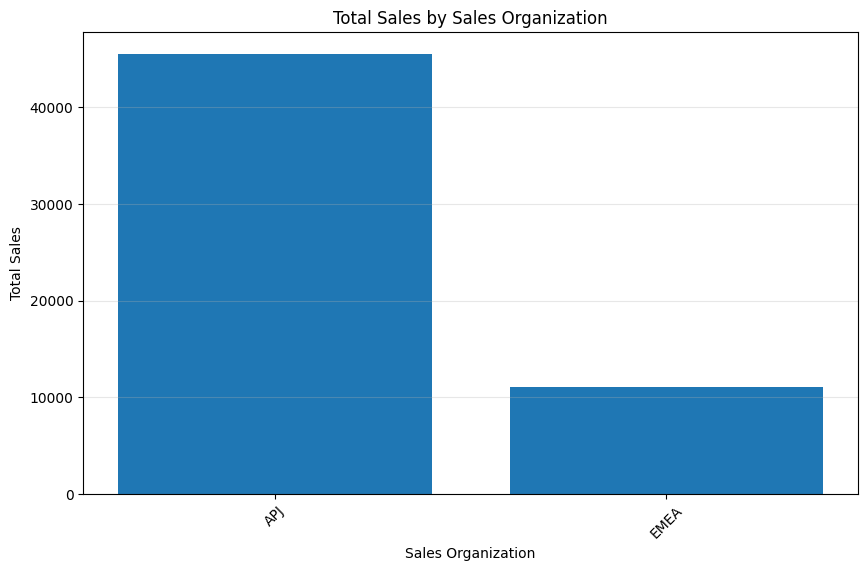

In [ ]:
import matplotlib.pyplot as plt

sales_by_salesorg = (
    pdJoinedSalesData
    .groupby('SALESORG')['TotalSales']
    .sum()
    .reset_index()
)

plt.figure(figsize=(10, 6))
plt.bar(
    sales_by_salesorg['SALESORG'],
    sales_by_salesorg['TotalSales']
)

plt.title('Total Sales by Sales Organization')
plt.xlabel('Sales Organization')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.show()